In [29]:
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110,"axes.titleweight": "bold"})
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)
RANDOM_STATE = 42

DATA_PATH = Path("kidney_cleaned.csv")
TARGET = "CKD"
NUMERIC_FEATURES = [
    "Age",
    "Blood_Pressure",
    "Urine_Specific_Gravity",
    "Urine_Albumin",
    "Urine_Sugar",
    "Random_Blood_Glucose",
    "Blood_Urea",
    "Serum_Creatinine",
    "Blood_Sodium",
    "Blood_Potassium",
    "Hemoglobin",
    "Packed_Cell_Volume",
    "White_Blood_Cell_Count",
    "Red_Blood_Cell_Count"
]

CATEGORICAL_FEATURES = [
    "Age_Group",
    "Red_Blood_Cells",
    "Pus_Cells",
    "Pus_Cell_Groups_Absent",
    "Pus_Cell_Groups_Unknown",
    "Pus_Cell_Groups_Present",
    "Bacteria_Absent",
    "Bacteria_Unknown",
    "Bacteria_Present",
    "Appetite_Poor",
    "Appetite_Good",
    "Appetite_Unknown"
]

ID_COLUMNS = []
DATETIME_COLUMNS = []
EXCLUDED_COLUMNS = []
TARGET_LABELS = {0: "No CKD", 1: "CKD"}
POSITIVE_CLASS = 1


ORDERED_FEATURE = None
ORDERED_EDGES = None
INTERACTION_FEATURES = None
CATEGORICAL_PAIR = None
PLACEHOLDER_VALUES = {}

MAX_SCATTER_ROWS = 6000
MIN_GROUP_SIZE = 30

In [19]:
DATA_PATH = Path("kidney_cleaned.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "The file 'kidney_cleaned.csv' was not found. "
        "Place it beside the notebook or update DATA_PATH."
    )

raw = pd.read_csv(DATA_PATH)

print(
    f"Loaded {DATA_PATH.name}: "
    f"{raw.shape[0]:,} rows × {raw.shape[1]} columns"
)

display(raw.head())
raw.info()


Loaded kidney_cleaned.csv: 15,049 rows × 27 columns


,Edad,Presión arterial,Gravedad específica de la orina,Albúmina en orina,Azúcar en orina,Glóbulos rojos,Células de pus,Glucosa en sangre aleatoria,Urea en sangre,Creatinina sérica,Sodio en sangre,Potasio en sangre,Hemoglobina,Volumen corpuscular empaquetado,Recuento de glóbulos blancos,Recuento de glóbulos rojos,Insuficiencia renal crónica,Grupos de células de pus_ausente,Grupos de células de pus_desconocido,Grupos de células de pus_presente,Bacterias_ausente,Bacterias_desconocido,Bacterias_presente,Apetito_bajo,Apetito_bueno,Apetito_desconocido,Age_Group
0,48,178,1010.0,2.0,2,1,1,298,195.0,9.08,124.0,6.0,8.0,25.0,11319,3.8,1,0,0,1,0,0,1,1,0,0,40_59
1,7,138,1014.0,1.0,4,1,1,187,111.0,7.88,133.0,6.8,11.0,27.0,11018,2.9,1,0,0,1,0,0,1,1,0,0,Under_18
2,62,165,1014.0,2.0,5,1,1,286,149.0,12.89,130.0,6.0,8.0,27.0,5479,4.4,1,0,0,1,0,0,1,1,0,0,60_plus
3,48,141,1007.0,4.0,4,1,1,165,98.0,5.02,133.0,5.8,11.0,35.0,7817,3.2,1,0,0,1,0,0,1,1,0,0,40_59
4,51,175,1015.0,4.0,5,1,1,179,152.0,7.32,132.0,6.8,9.0,30.0,3055,3.9,1,0,0,1,0,0,1,1,0,0,40_59


<class 'pandas.DataFrame'>
RangeIndex: 15049 entries, 0 to 15048
Data columns (total 27 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Edad                                  15049 non-null  int64  
 1   Presión arterial                      15049 non-null  int64  
 2   Gravedad específica de la orina       15049 non-null  float64
 3   Albúmina en orina                     15049 non-null  float64
 4   Azúcar en orina                       15049 non-null  int64  
 5   Glóbulos rojos                        15049 non-null  int64  
 6   Células de pus                        15049 non-null  int64  
 7   Glucosa en sangre aleatoria           15049 non-null  int64  
 8   Urea en sangre                        15049 non-null  float64
 9   Creatinina sérica                     15049 non-null  float64
 10  Sodio en sangre                       15049 non-null  float64
 11  Potasio en sangre         

In [ ]:
COLUMN_RENAME = {
    "Edad": "Age",
    "Presión arterial": "Blood_Pressure",
    "Gravedad específica de la orina": "Urine_Specific_Gravity",
    "Albúmina en orina": "Urine_Albumin",
    "Azúcar en orina": "Urine_Sugar",
    "Glucosa en sangre aleatoria": "Random_Blood_Glucose",
    "Urea en sangre": "Blood_Urea",
    "Creatinina sérica": "Serum_Creatinine",
    "Sodio en sangre": "Blood_Sodium",
    "Potasio en sangre": "Blood_Potassium",
    "Hemoglobina": "Hemoglobin",
    "Volumen corpuscular empaquetado": "Packed_Cell_Volume",
    "Recuento de glóbulos blancos": "White_Blood_Cell_Count",
    "Recuento de glóbulos rojos": "Red_Blood_Cell_Count",
    "Insuficiencia renal crónica": "CKD",

    "Age_Group": "Age_Group",
    "Glóbulos rojos": "Red_Blood_Cells",
    "Células de pus": "Pus_Cells",

    "Grupos de células de pus_ausente": "Pus_Cell_Groups_Absent",
    "Grupos de células de pus_desconocido": "Pus_Cell_Groups_Unknown",
    "Grupos de células de pus_presente": "Pus_Cell_Groups_Present",

    "Bacterias_ausente": "Bacteria_Absent",
    "Bacterias_desconocido": "Bacteria_Unknown",
    "Bacterias_presente": "Bacteria_Present",

    "Apetito_bajo": "Appetite_Poor",
    "Apetito_bueno": "Appetite_Good",
    "Apetito_desconocido": "Appetite_Unknown"
}

missing_names = set(raw.columns) - set(COLUMN_RENAME)

if missing_names:
    raise ValueError(f"Columns without English names: {missing_names}")


raw = raw.rename(columns=COLUMN_RENAME)


print("New column names:")
print(raw.columns.tolist())

print("\nDataset shape:", raw.shape)

In [30]:
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_n": raw.isna().sum(),
    "unique_nonmissing": raw.nunique(),
    "examples": [
        ", ".join(map(str, raw[c].dropna().unique()[:5])) for c in raw.columns]
})
display(profile)

roles = {
    "target": [TARGET],
    "numerical": NUMERIC_FEATURES,
    "categorical": CATEGORICAL_FEATURES,
    "ID": ID_COLUMNS,
    "datetime": DATETIME_COLUMNS,
    "excluded": EXCLUDED_COLUMNS
}

assigned = [c for cols in roles.values() for c in cols]
assert len(assigned) == len(set(assigned)), ("A column has more than one role.")
assert set(assigned) == set(raw.columns), ("Review missing, extra, or unassigned column names.")
assert all(pd.api.types.is_numeric_dtype(raw[c]) for c in NUMERIC_FEATURES), "Review numeric parsing."
assert not raw.empty, "The dataset has no rows."
display(pd.DataFrame([(c, role) for role, cols in roles.items() for c in cols],
                     columns=["column", "analysis_role"]))

,dtype,missing_n,unique_nonmissing,examples
Age,int64,0,75,"48, 7, 62, 51, 60"
Blood_Pressure,int64,0,93,"178, 138, 165, 141, 175"
Urine_Specific_Gravity,float64,0,522,"1010.0, 1014.0, 1007.0, 1015.0, 1009.0"
Urine_Albumin,float64,0,5050,"2.0, 1.0, 4.0, 5.0, 3.0"
Urine_Sugar,int64,0,959,"2, 4, 5, 3, 1"
Red_Blood_Cells,int64,0,2,"1, 0"
Pus_Cells,int64,0,2,"1, 0"
Random_Blood_Glucose,int64,0,231,"298, 187, 286, 165, 179"
Blood_Urea,float64,0,1165,"195.0, 111.0, 149.0, 98.0, 152.0"
Serum_Creatinine,float64,0,353,"9.08, 7.88, 12.89, 5.02, 7.32"


,column,analysis_role
0,CKD,target
1,Age,numerical
2,Blood_Pressure,numerical
3,Urine_Specific_Gravity,numerical
4,Urine_Albumin,numerical
5,Urine_Sugar,numerical
6,Random_Blood_Glucose,numerical
7,Blood_Urea,numerical
8,Serum_Creatinine,numerical
9,Blood_Sodium,numerical


,missing_n,missing_pct
Age,0,0.0
Blood_Pressure,0,0.0
Urine_Specific_Gravity,0,0.0
Urine_Albumin,0,0.0
Urine_Sugar,0,0.0
Red_Blood_Cells,0,0.0
Pus_Cells,0,0.0
Random_Blood_Glucose,0,0.0
Blood_Urea,0,0.0
Serum_Creatinine,0,0.0


Repeated rows beyond the first identical row: 1
Constant/all-missing columns: []


""


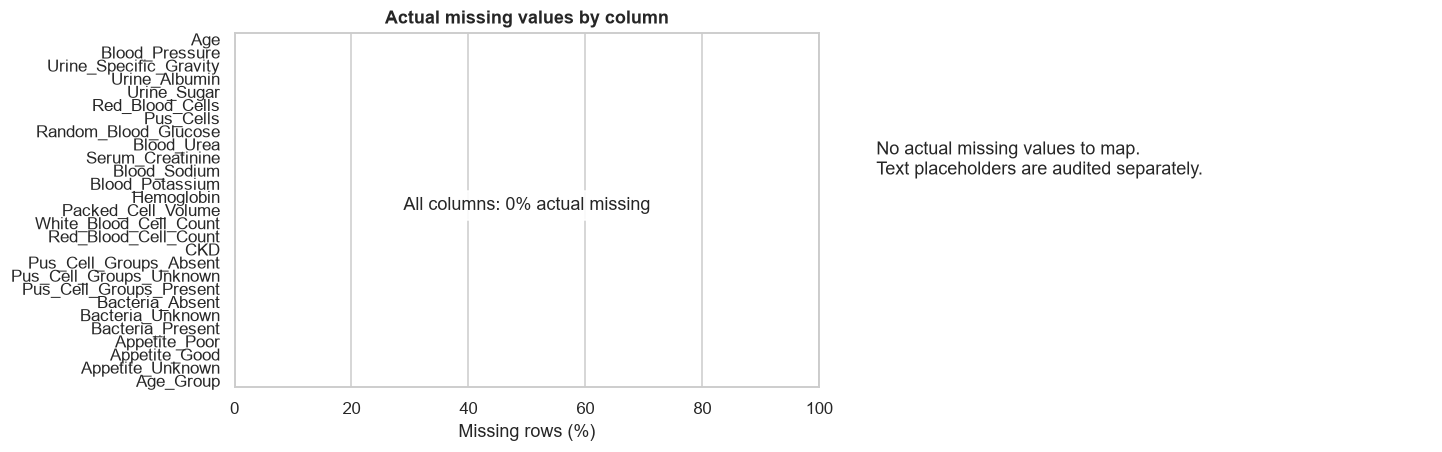

In [32]:
missing = raw.isna().sum().sort_values(ascending=False)
quality = pd.DataFrame({"missing_n": missing, "missing_pct": missing / len(raw) * 100})
display(quality)
print(f"Repeated rows beyond the first identical row: {raw.duplicated().sum():,}")
print("Constant/all-missing columns:", raw.columns[raw.nunique(dropna=True) <= 1].tolist())

placeholder_rows = []
for col, values in PLACEHOLDER_VALUES.items():
    if col in raw:
        for value in values:
            n = int(raw[col].eq(value).sum())
            placeholder_rows.append({"column": col, "recorded_value": value,
                                     "rows": n, "percent": 100 * n / len(raw)})
display(pd.DataFrame(placeholder_rows))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
missing_pct = quality["missing_pct"].rename_axis("column").reset_index()
sns.barplot(data=missing_pct, x="missing_pct", y="column", color="#3783a5", ax=axes[0])
axes[0].set(title="Actual missing values by column", xlabel="Missing rows (%)", ylabel="")
axes[0].set_xlim(0, 100)
if missing.sum() == 0:
    axes[0].text(0.5, 0.5, "All columns: 0% actual missing", transform=axes[0].transAxes,
                 ha="center", bbox={"facecolor":"white", "alpha":0.9})
    axes[1].axis("off")
    axes[1].text(0.05, 0.6, "No actual missing values to map.\nText placeholders are audited separately.",
                 transform=axes[1].transAxes)
else:
    missing_sample = raw.sample(min(300, len(raw)), random_state=RANDOM_STATE)
    sns.heatmap(missing_sample.isna(), cbar=False, yticklabels=False, ax=axes[1],
                cmap=["#e7f0f5", "#ce5d45"], vmin=0, vmax=1)
    axes[1].set(title="Missingness pattern: random sample, up to 300 rows", ylabel="Sampled rows")
plt.show()

In [33]:
for col in CATEGORICAL_FEATURES:
    print(f"\n{col}")
    display(raw[col].value_counts(dropna=False).rename("rows").to_frame())

if NUMERIC_FEATURES:
    display(raw[NUMERIC_FEATURES].describe().T)
    display(pd.DataFrame({
        "most_frequent_value": [raw[c].mode().iloc[0] if not raw[c].mode().empty else np.nan
                                for c in NUMERIC_FEATURES],
        "frequency_pct": [100 * raw[c].value_counts(normalize=True).iloc[0]
                          if raw[c].notna().any() else np.nan for c in NUMERIC_FEATURES]
    }, index=NUMERIC_FEATURES))


Age_Group


,rows
Age_Group,
60_plus,6115
40_59,6030
18_39,1812
Under_18,1092



Red_Blood_Cells


,rows
Red_Blood_Cells,
0,7689
1,7360



Pus_Cells


...

,rows
Appetite_Good,
1,8425
0,6624



Appetite_Unknown


,rows
Appetite_Unknown,
0,15048
1,1


,count,mean,std,min,25%,50%,75%,max
Age,15049.0,52.101,17.555,2.0,45.00,55.0,65.00,90.0
Blood_Pressure,15049.0,93.233,19.907,50.0,80.00,94.0,107.00,180.0
Urine_Specific_Gravity,15049.0,541.411,502.973,10.0,12.63,1015.0,1020.00,1025.0
Urine_Albumin,15049.0,228.292,314.184,0.0,0.00,1.0,452.20,989.9
Urine_Sugar,15049.0,154.295,248.574,0.0,0.00,1.0,200.00,1000.0
Random_Blood_Glucose,15049.0,157.609,62.356,70.0,105.00,139.0,208.00,300.0
Blood_Urea,15049.0,59.641,42.506,10.0,25.00,40.0,93.50,200.0
Serum_Creatinine,15049.0,3.223,5.478,0.4,0.94,1.4,3.25,76.0
Blood_Sodium,15049.0,138.584,5.823,120.0,135.00,139.0,143.00,150.0
Blood_Potassium,15049.0,5.385,0.860,3.5,4.79,5.4,6.09,7.5


,most_frequent_value,frequency_pct
Age,45.0,4.698
Blood_Pressure,70.0,13.529
Urine_Specific_Gravity,1017.0,5.083
Urine_Albumin,1.0,25.789
Urine_Sugar,0.0,25.603
Random_Blood_Glucose,140.0,0.917
Blood_Urea,24.0,1.794
Serum_Creatinine,1.2,6.306
Blood_Sodium,138.0,5.203
Blood_Potassium,5.9,1.967


In [34]:
print(f"Rows excluded from class comparisons because target is missing: {raw[TARGET].isna().sum():,}")
df = raw.loc[raw[TARGET].notna()].copy()
assert not df.empty, "No labeled rows remain."
if NUMERIC_FEATURES:
    assert not np.isinf(df[NUMERIC_FEATURES].to_numpy(dtype=float)).any(), "Investigate infinite values."
    NUMERIC_FEATURES = [c for c in NUMERIC_FEATURES if df[c].notna().any()]
    print("Numerical features with at least one observed value:", NUMERIC_FEATURES)

observed_classes = sorted(df[TARGET].unique(), key=str)
label_lookup = {value: str(TARGET_LABELS.get(value, value)) for value in observed_classes}
assert len(set(label_lookup.values())) == len(label_lookup), "Target display labels must be distinct."
CLASS_COL = "__target_label__"
assert CLASS_COL not in df.columns
df[CLASS_COL] = df[TARGET].map(label_lookup)
class_order = [label_lookup[v] for v in observed_classes]
class_colors = dict(zip(class_order, sns.color_palette("colorblind", len(class_order))))
IS_BINARY = len(observed_classes) == 2 and POSITIVE_CLASS in observed_classes

for col in CATEGORICAL_FEATURES:
    df[col] = df[col].astype("string").fillna("<Missing>")
category_orders = {c: df[c].value_counts().index.tolist() for c in CATEGORICAL_FEATURES}
print(f"Analysis population: {len(df):,} rows; classes: {class_order}")

Rows excluded from class comparisons because target is missing: 0
Numerical features with at least one observed value: ['Age', 'Blood_Pressure', 'Urine_Specific_Gravity', 'Urine_Albumin', 'Urine_Sugar', 'Random_Blood_Glucose', 'Blood_Urea', 'Serum_Creatinine', 'Blood_Sodium', 'Blood_Potassium', 'Hemoglobin', 'Packed_Cell_Volume', 'White_Blood_Cell_Count', 'Red_Blood_Cell_Count']
Analysis population: 15,049 rows; classes: ['No CKD', 'CKD']


In [35]:
categorical_columns = CATEGORICAL_FEATURES
numerical_columns = NUMERIC_FEATURES
class_col = CLASS_COL

def subplot_grid(n, ncols=2, width=6, height=4):
    """Return a figure and n usable axes; hide any unused panels."""
    ncols = min(ncols, max(1, n))
    nrows = int(np.ceil(max(1, n) / ncols))
    fig, axes = plt.subplots(nrows,ncols,figsize=(width * ncols, height * nrows),
                             squeeze=False, constrained_layout=True)
    flat = axes.ravel()
    for ax in flat[n:]:
        ax.set_visible(False)

    return fig, flat[:n]


def label_bars(ax, fmt="%.1f"):
    for container in ax.containers:
        ax.bar_label(container,fmt=fmt,fontsize=8,padding=3)
    ax.margins(y=0.18)

In [36]:
target_counts = df[CLASS_COL].value_counts().reindex(class_order)
target_summary = pd.DataFrame({"rows": target_counts, "percent": target_counts/len(df)*100})
print(target_counts)
print(target_summary)

__target_label__
No CKD    7696
CKD       7353
Name: count, dtype: int64
                  rows  percent
__target_label__               
No CKD            7696    51.14
CKD               7353    48.86


C:\Users\mg050\AppData\Local\Temp\ipykernel_6968\658464438.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=CLASS_COL, order=class_order, palette=class_colors,


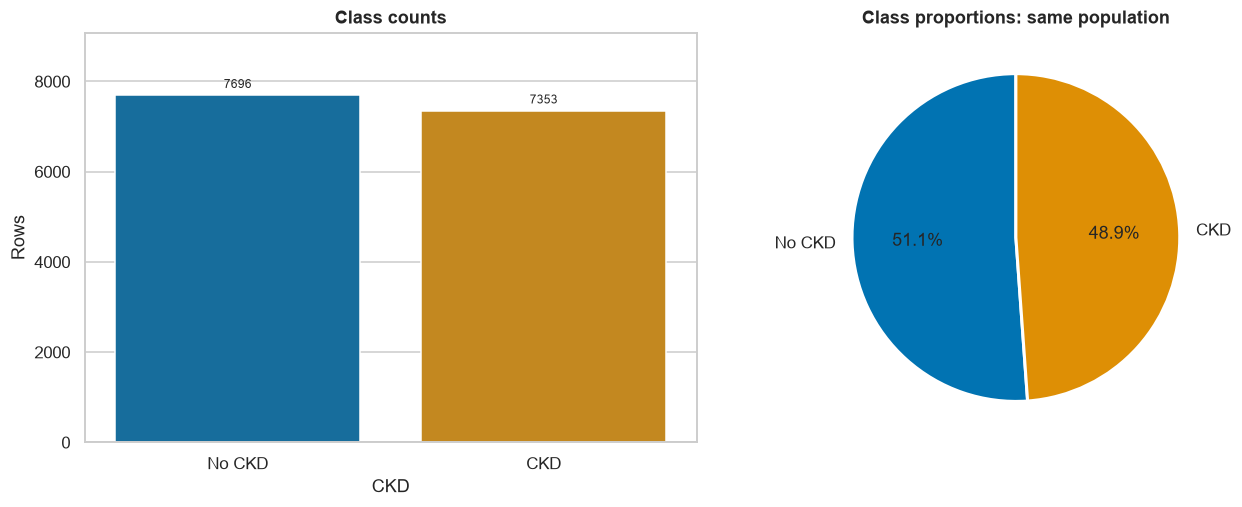

Majority-class baseline on these rows: 51.14%


In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
sns.countplot(data=df, x=CLASS_COL, order=class_order, palette=class_colors,
              legend=False, ax=axes[0])
axes[0].set(title="Class counts", xlabel=TARGET, ylabel="Rows")
label_bars(axes[0], "%.0f")
if len(class_order) <= 5:
    axes[1].pie(target_counts, labels=class_order, autopct="%1.1f%%", startangle=90,
                colors=[class_colors[c] for c in class_order],
                wedgeprops={"edgecolor":"white", "linewidth":2})
    axes[1].set_title("Class proportions: same population")
else:
    axes[1].axis("off")
    axes[1].text(0, 0.5, "Pie omitted: use the countplot and percentage table for many classes.")
plt.show()
print(f"Majority-class baseline on these rows: {target_counts.max()/len(df):.2%}")

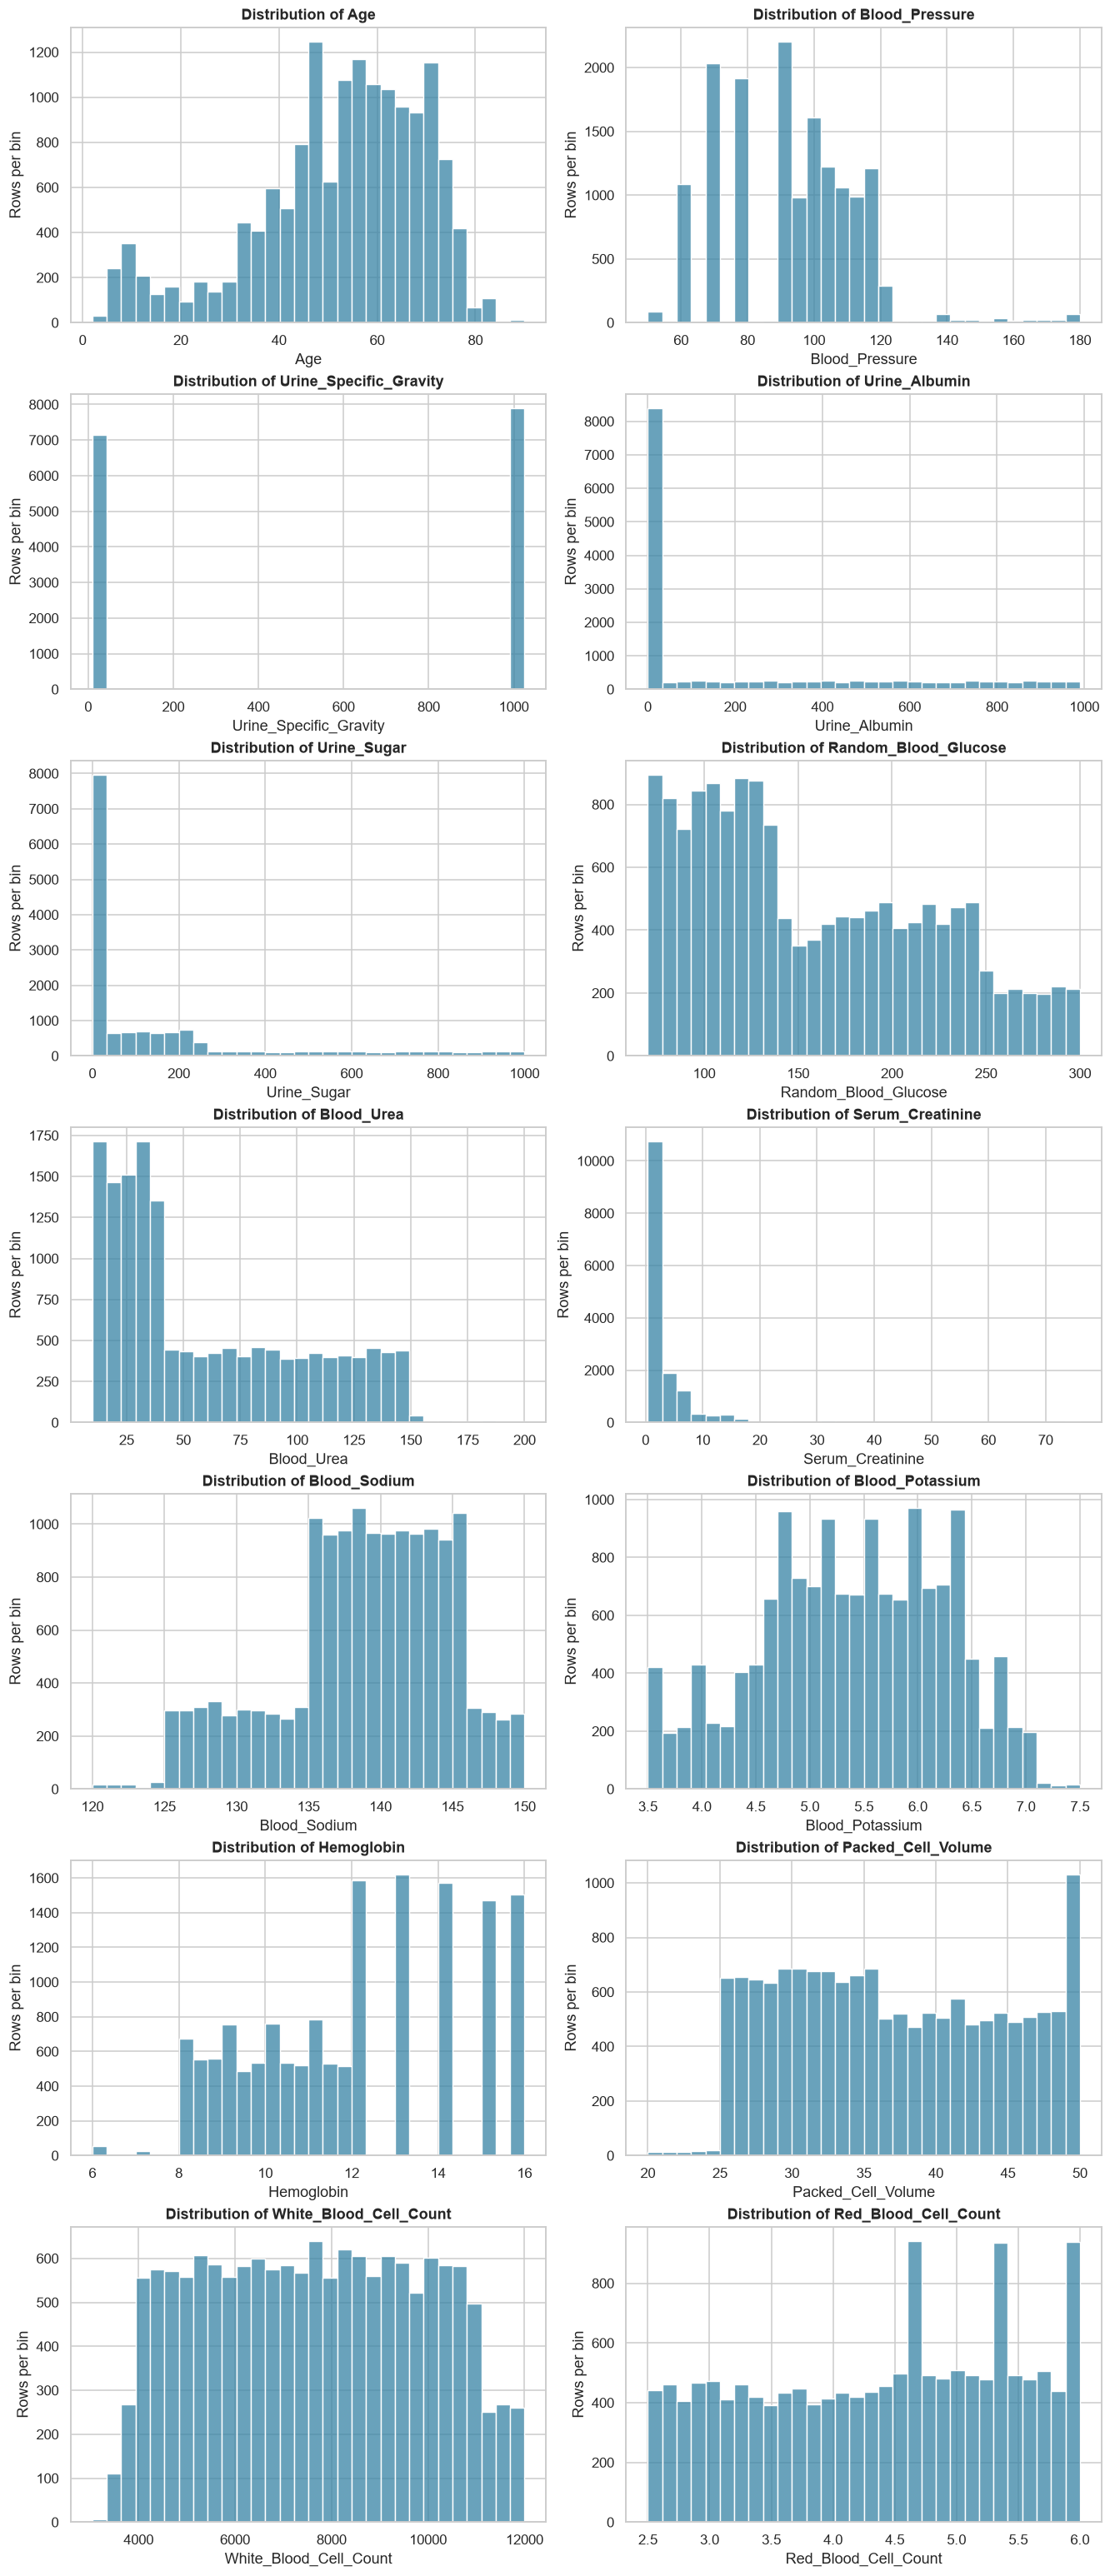

In [38]:
if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES)) 
    for ax, col in zip(axes, NUMERIC_FEATURES): 
        sns.histplot(data=df, x=col, bins=30, color="#3783a5", ax=ax)
        ax.set(title=f"Distribution of {col}", ylabel="Rows per bin")
    plt.show()

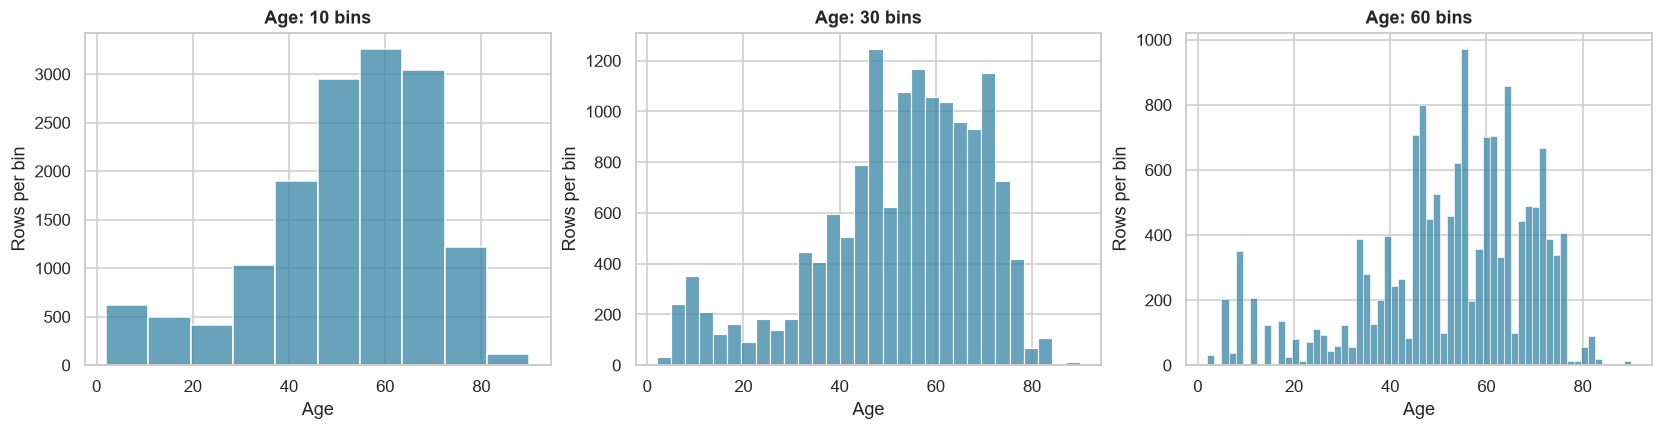

In [39]:
if NUMERIC_FEATURES:
    example_feature = NUMERIC_FEATURES[0]
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True, constrained_layout=True)
    for ax, bins in zip(axes, [10, 30, 60]):
        sns.histplot(data=df, x=example_feature, bins=bins, color="#3783a5", ax=ax)
        ax.set(title=f"{example_feature}: {bins} bins", ylabel="Rows per bin")
    plt.show()

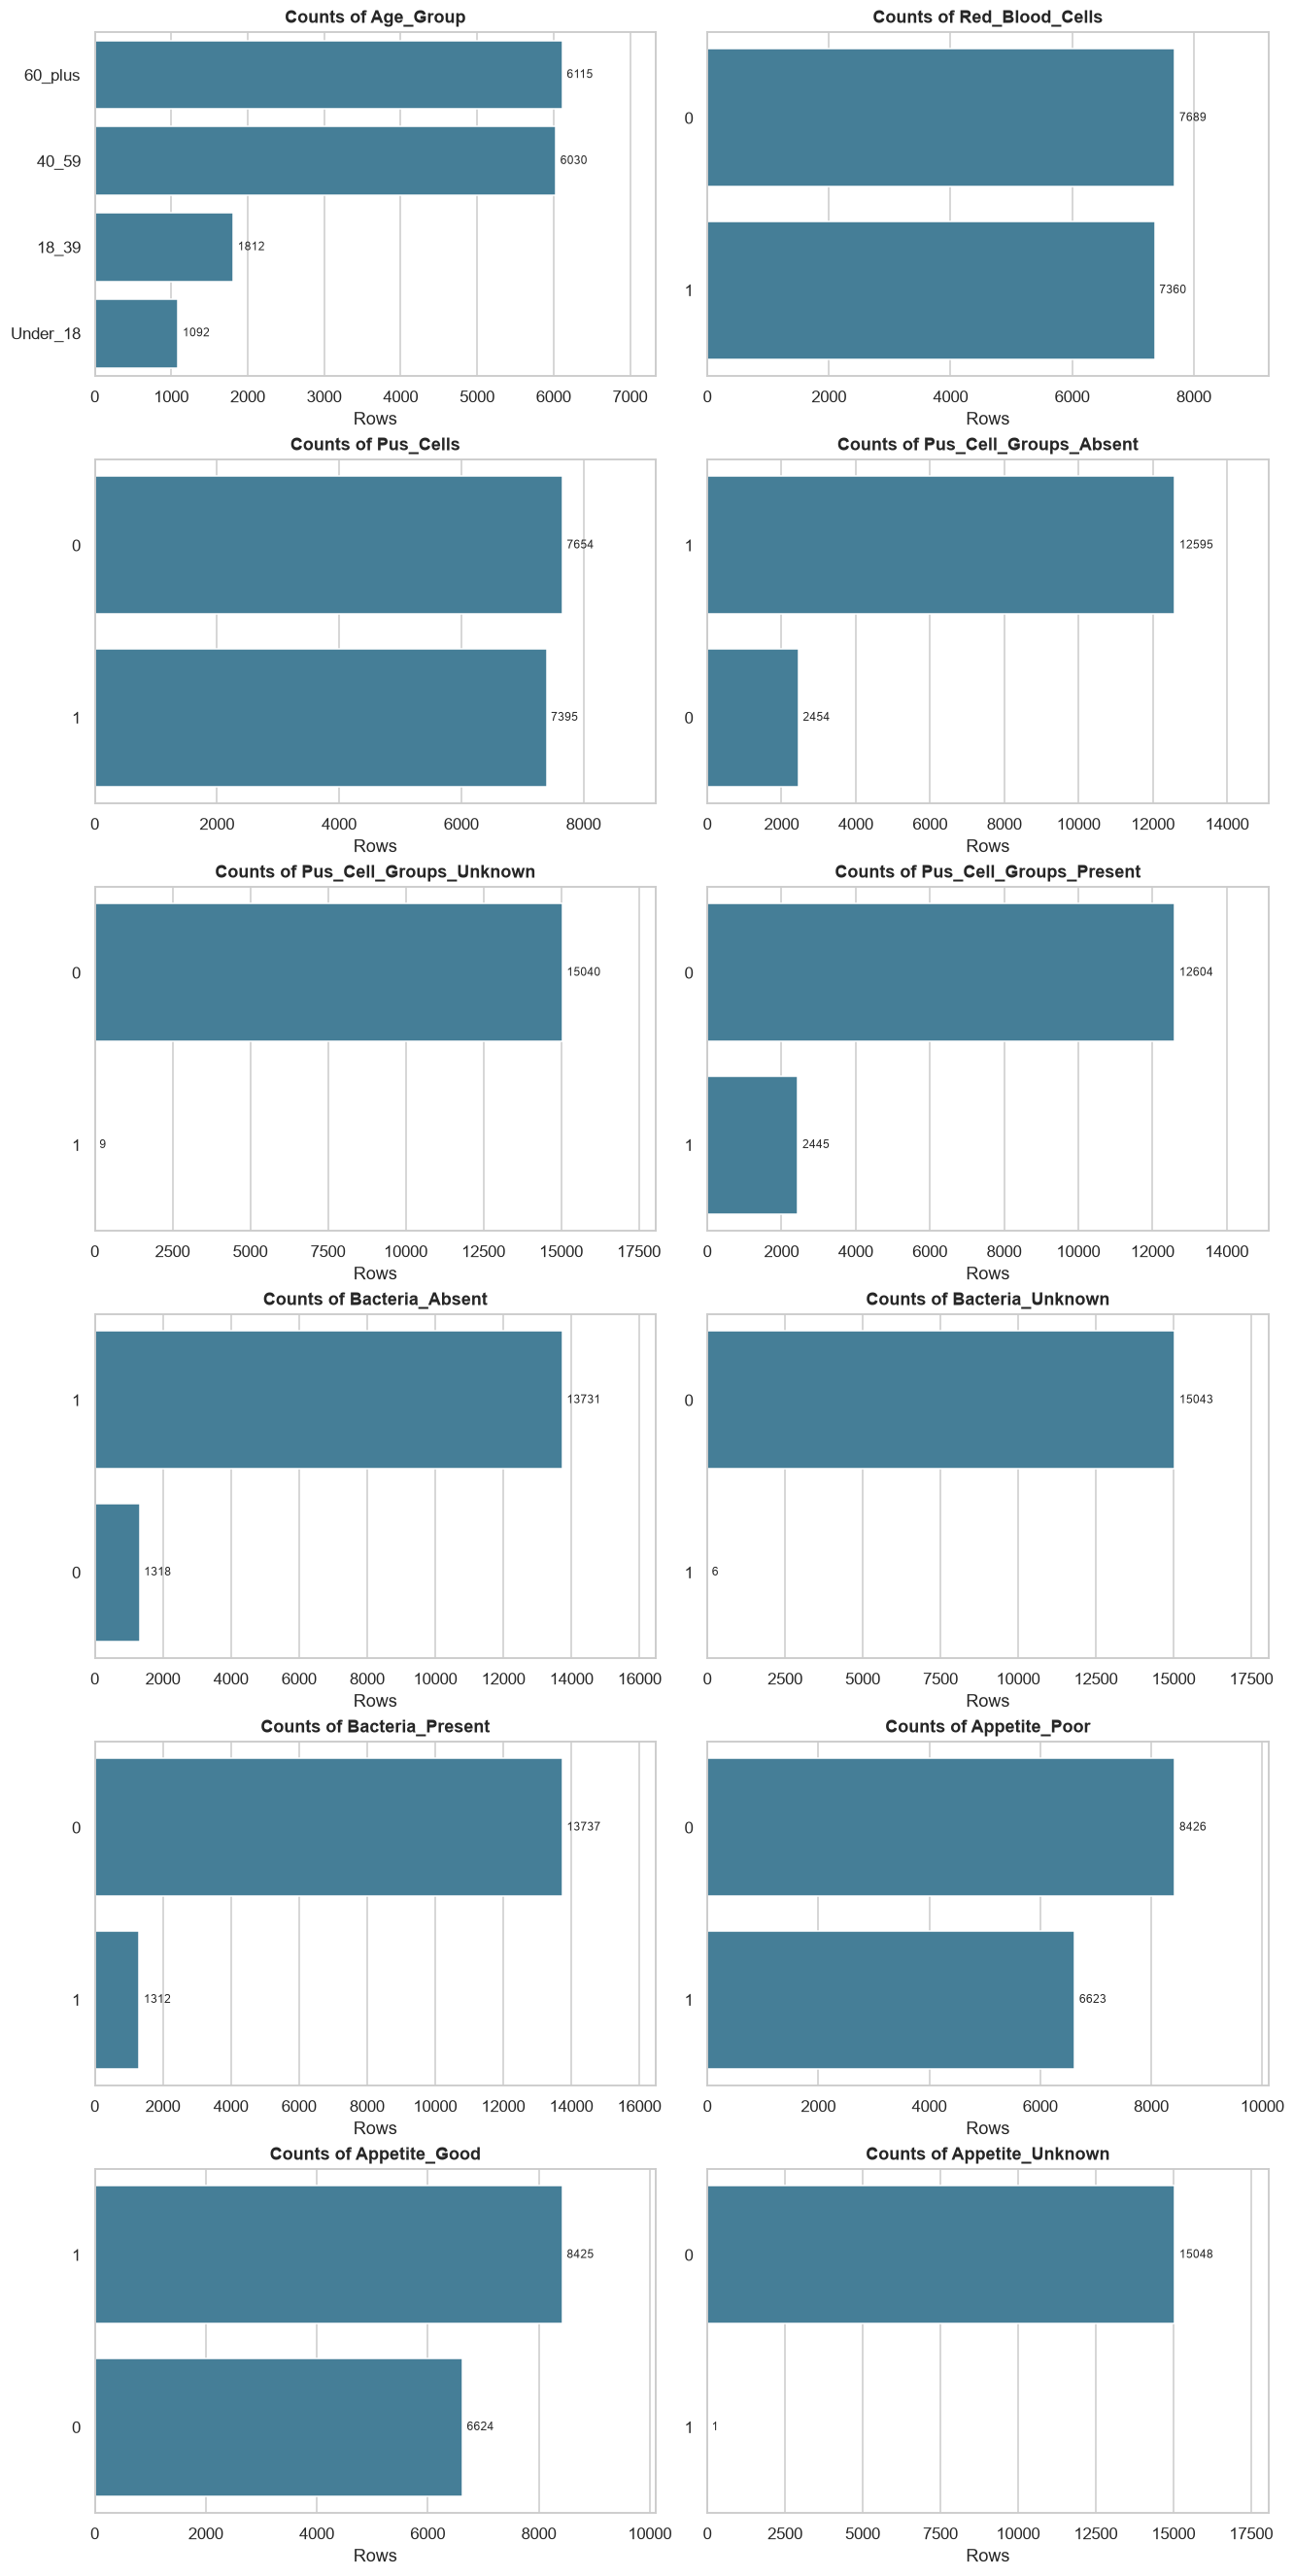

In [40]:
if CATEGORICAL_FEATURES:
    fig, axes = subplot_grid(len(CATEGORICAL_FEATURES))
    for ax, col in zip(axes, CATEGORICAL_FEATURES):
        sns.countplot(data=df, y=col, order=category_orders[col], color="#3783a5", ax=ax)
        ax.set(title=f"Counts of {col}", xlabel="Rows", ylabel="")
        for container in ax.containers:
            ax.bar_label(container, fmt="%.0f", fontsize=8, padding=3)
        ax.margins(x=0.2)
    plt.show()

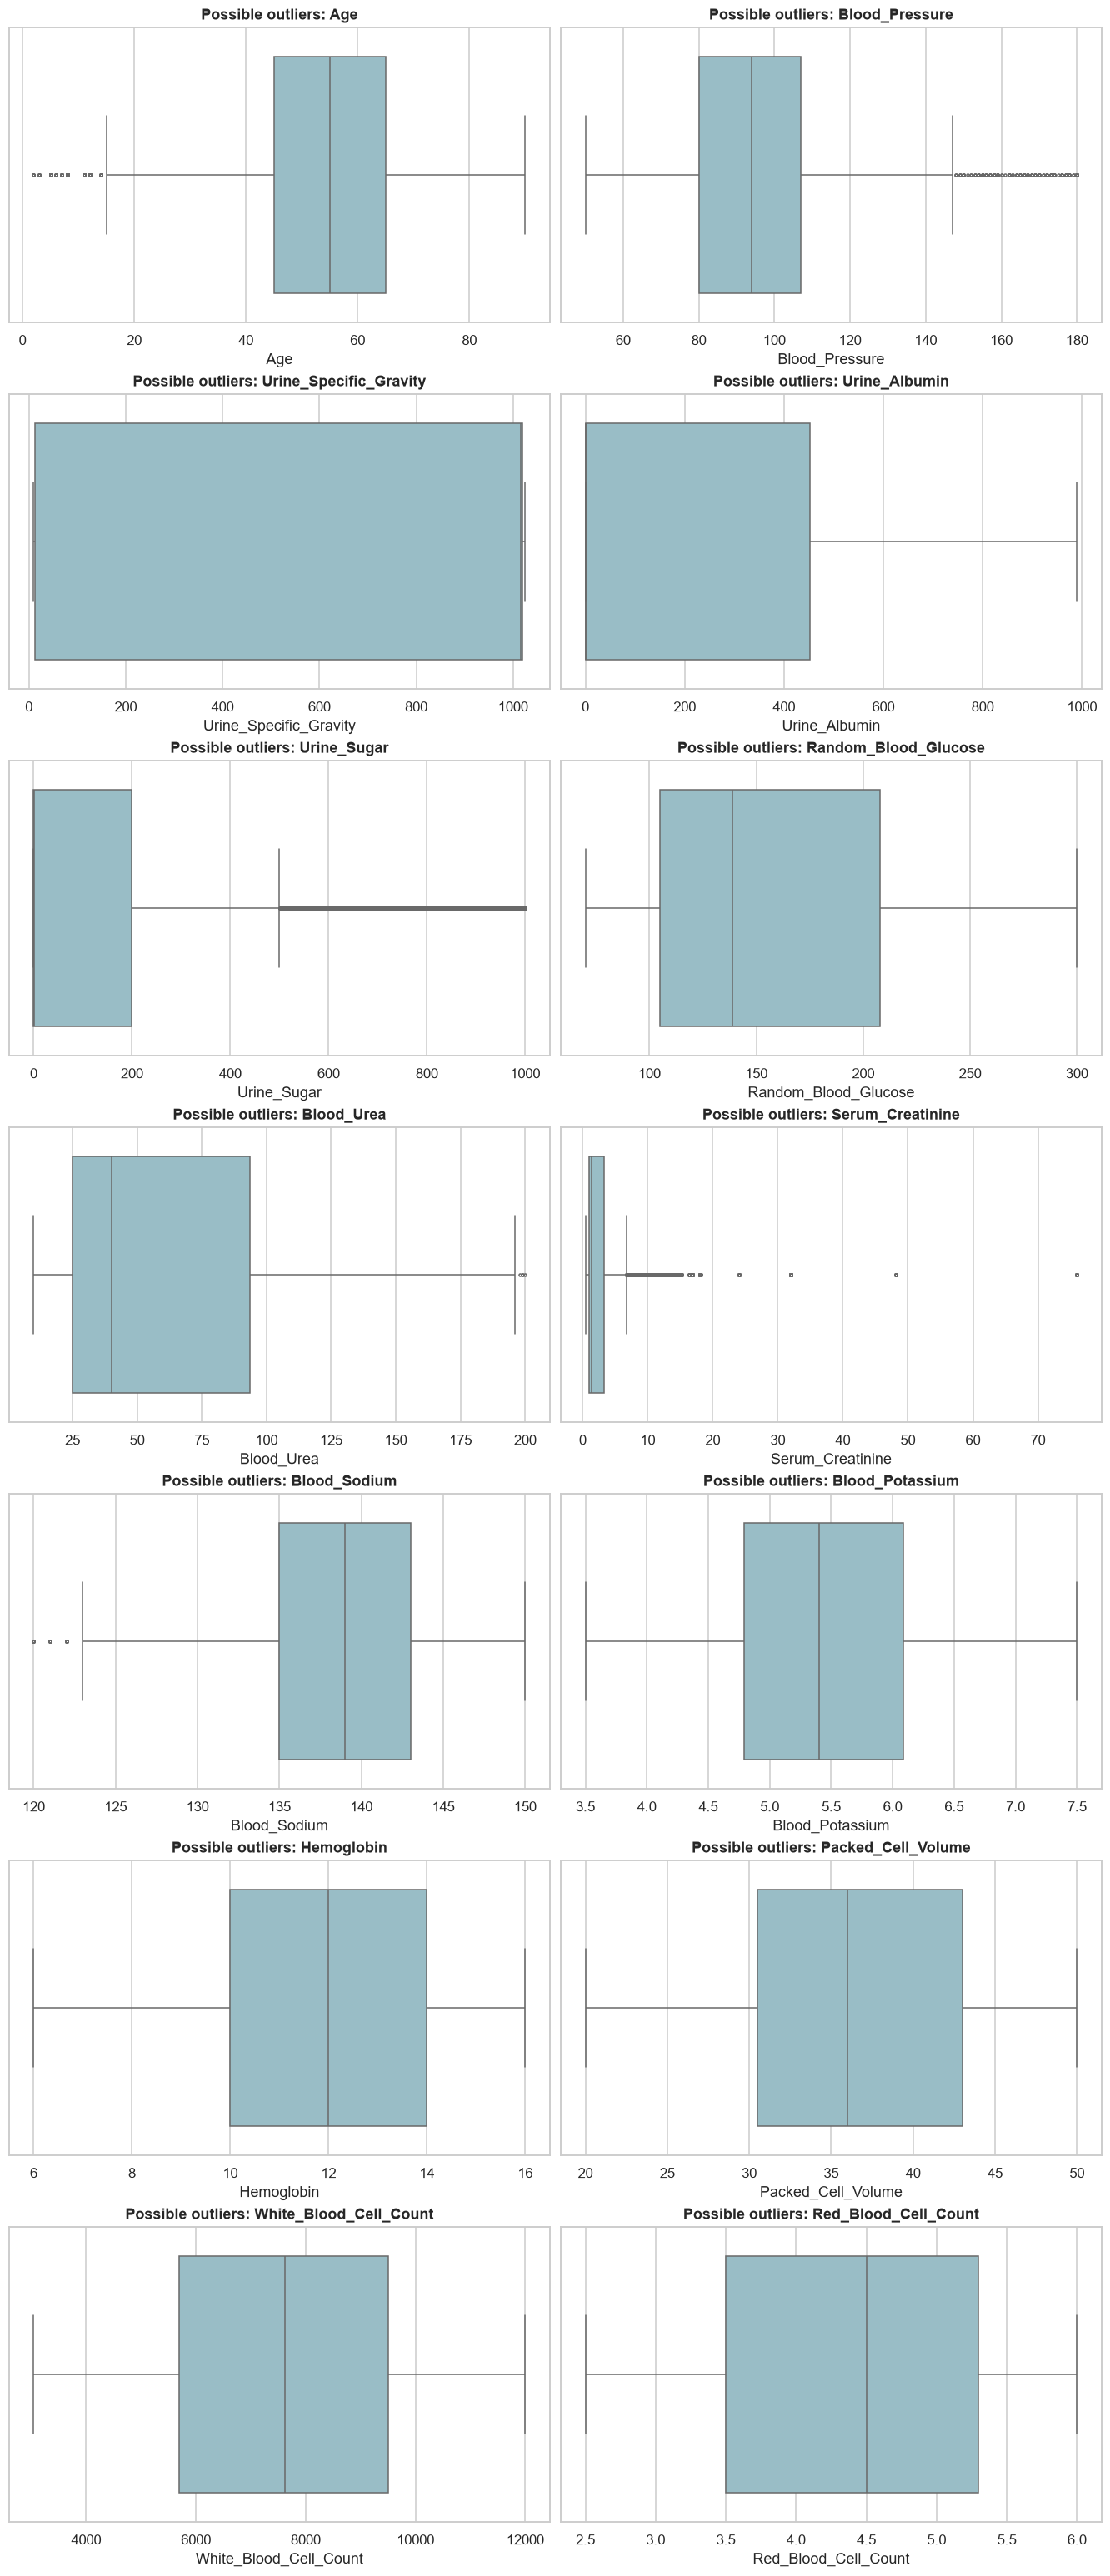

,feature,Q1,Q3,IQR,lower_fence,upper_fence,flagged_n,observed_n,flagged_pct
0,Age,45.00,65.00,20.00,15.000,95.000,850,15049,5.648
1,Blood_Pressure,80.00,107.00,27.00,39.500,147.500,200,15049,1.329
2,Urine_Specific_Gravity,12.63,1020.00,1007.37,-1498.425,2531.055,0,15049,0.000
3,Urine_Albumin,0.00,452.20,452.20,-678.300,1130.500,0,15049,0.000
4,Urine_Sugar,0.00,200.00,200.00,-300.000,500.000,1808,15049,12.014
5,Random_Blood_Glucose,105.00,208.00,103.00,-49.500,362.500,0,15049,0.000
6,Blood_Urea,25.00,93.50,68.50,-77.750,196.250,4,15049,0.027
7,Serum_Creatinine,0.94,3.25,2.31,-2.525,6.715,1536,15049,10.207
8,Blood_Sodium,135.00,143.00,8.00,123.000,155.000,52,15049,0.346
9,Blood_Potassium,4.79,6.09,1.30,2.840,8.040,0,15049,0.000


Flagged rows have been retained.


In [41]:
outlier_rows = []
if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES))
    for ax, col in zip(axes, NUMERIC_FEATURES):
        sns.boxplot(data=df, x=col, color="#91c2ce", fliersize=2, ax=ax)
        ax.set_title(f"Possible outliers: {col}")
        x = df[col].dropna()
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
        flagged = (x < lower) | (x > upper)
        outlier_rows.append({"feature": col, "Q1": q1, "Q3": q3, "IQR": iqr,
                             "lower_fence": lower, "upper_fence": upper,
                             "flagged_n": int(flagged.sum()), "observed_n": len(x),
                             "flagged_pct": flagged.mean()*100})
    plt.show()
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)
print("Flagged rows have been retained.")

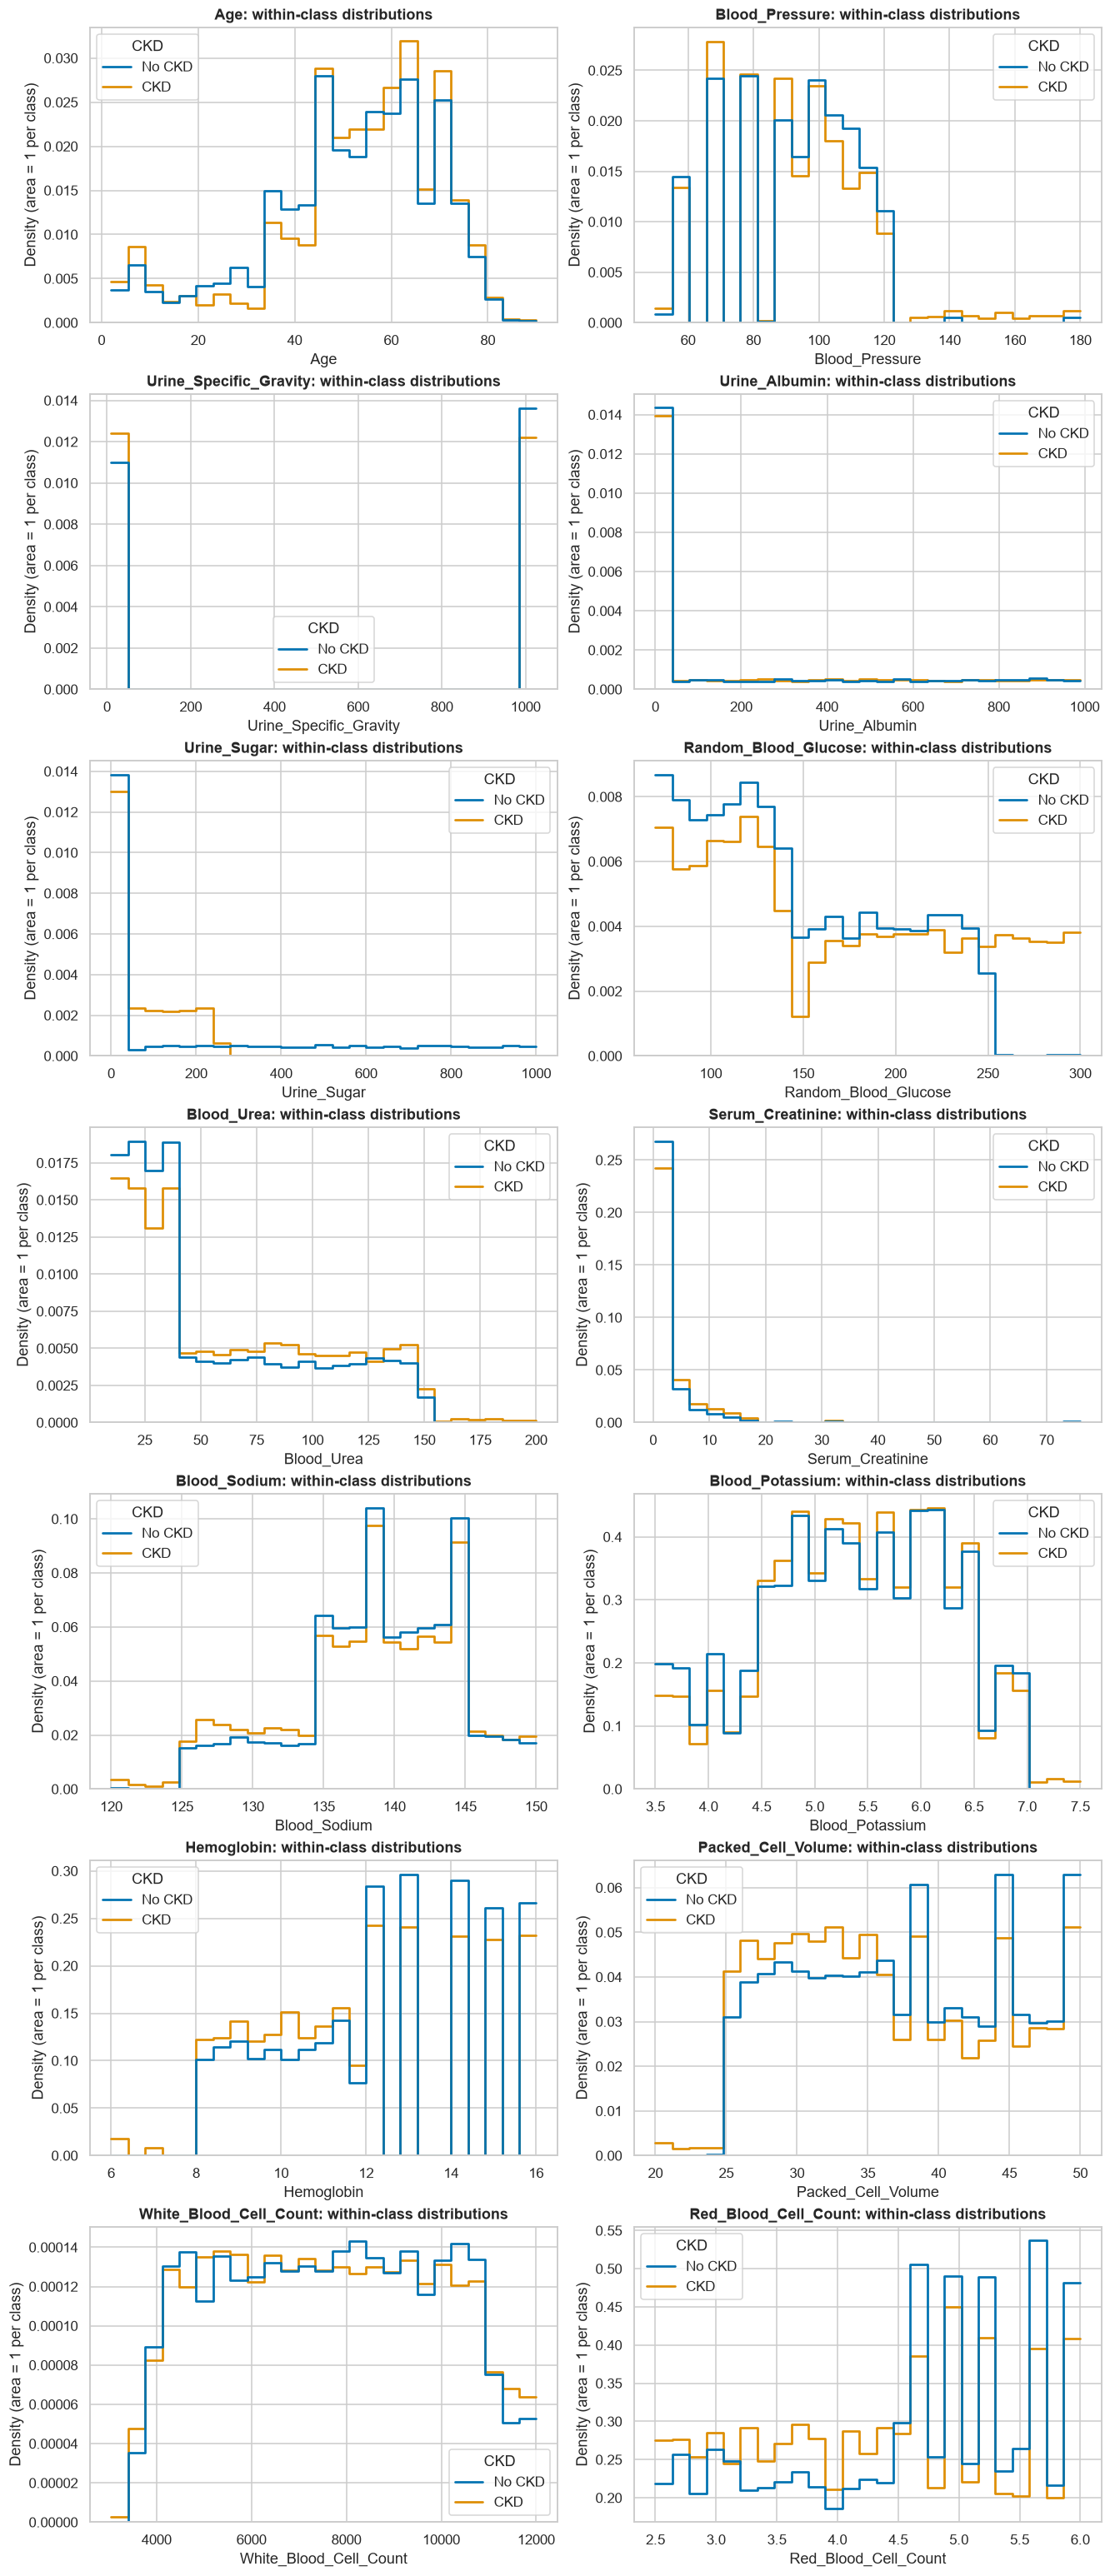

In [42]:
if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES))
    for ax, col in zip(axes, NUMERIC_FEATURES):
        sns.histplot(data=df, x=col, hue=CLASS_COL, hue_order=class_order,
                     palette=class_colors, bins=25, stat="density", common_norm=False,
                     common_bins=True, element="step", fill=False, linewidth=1.8, ax=ax)
        ax.set(title=f"{col}: within-class distributions", ylabel="Density (area = 1 per class)")
        if ax.get_legend() is not None:
            ax.get_legend().set_title(TARGET)
    plt.show()

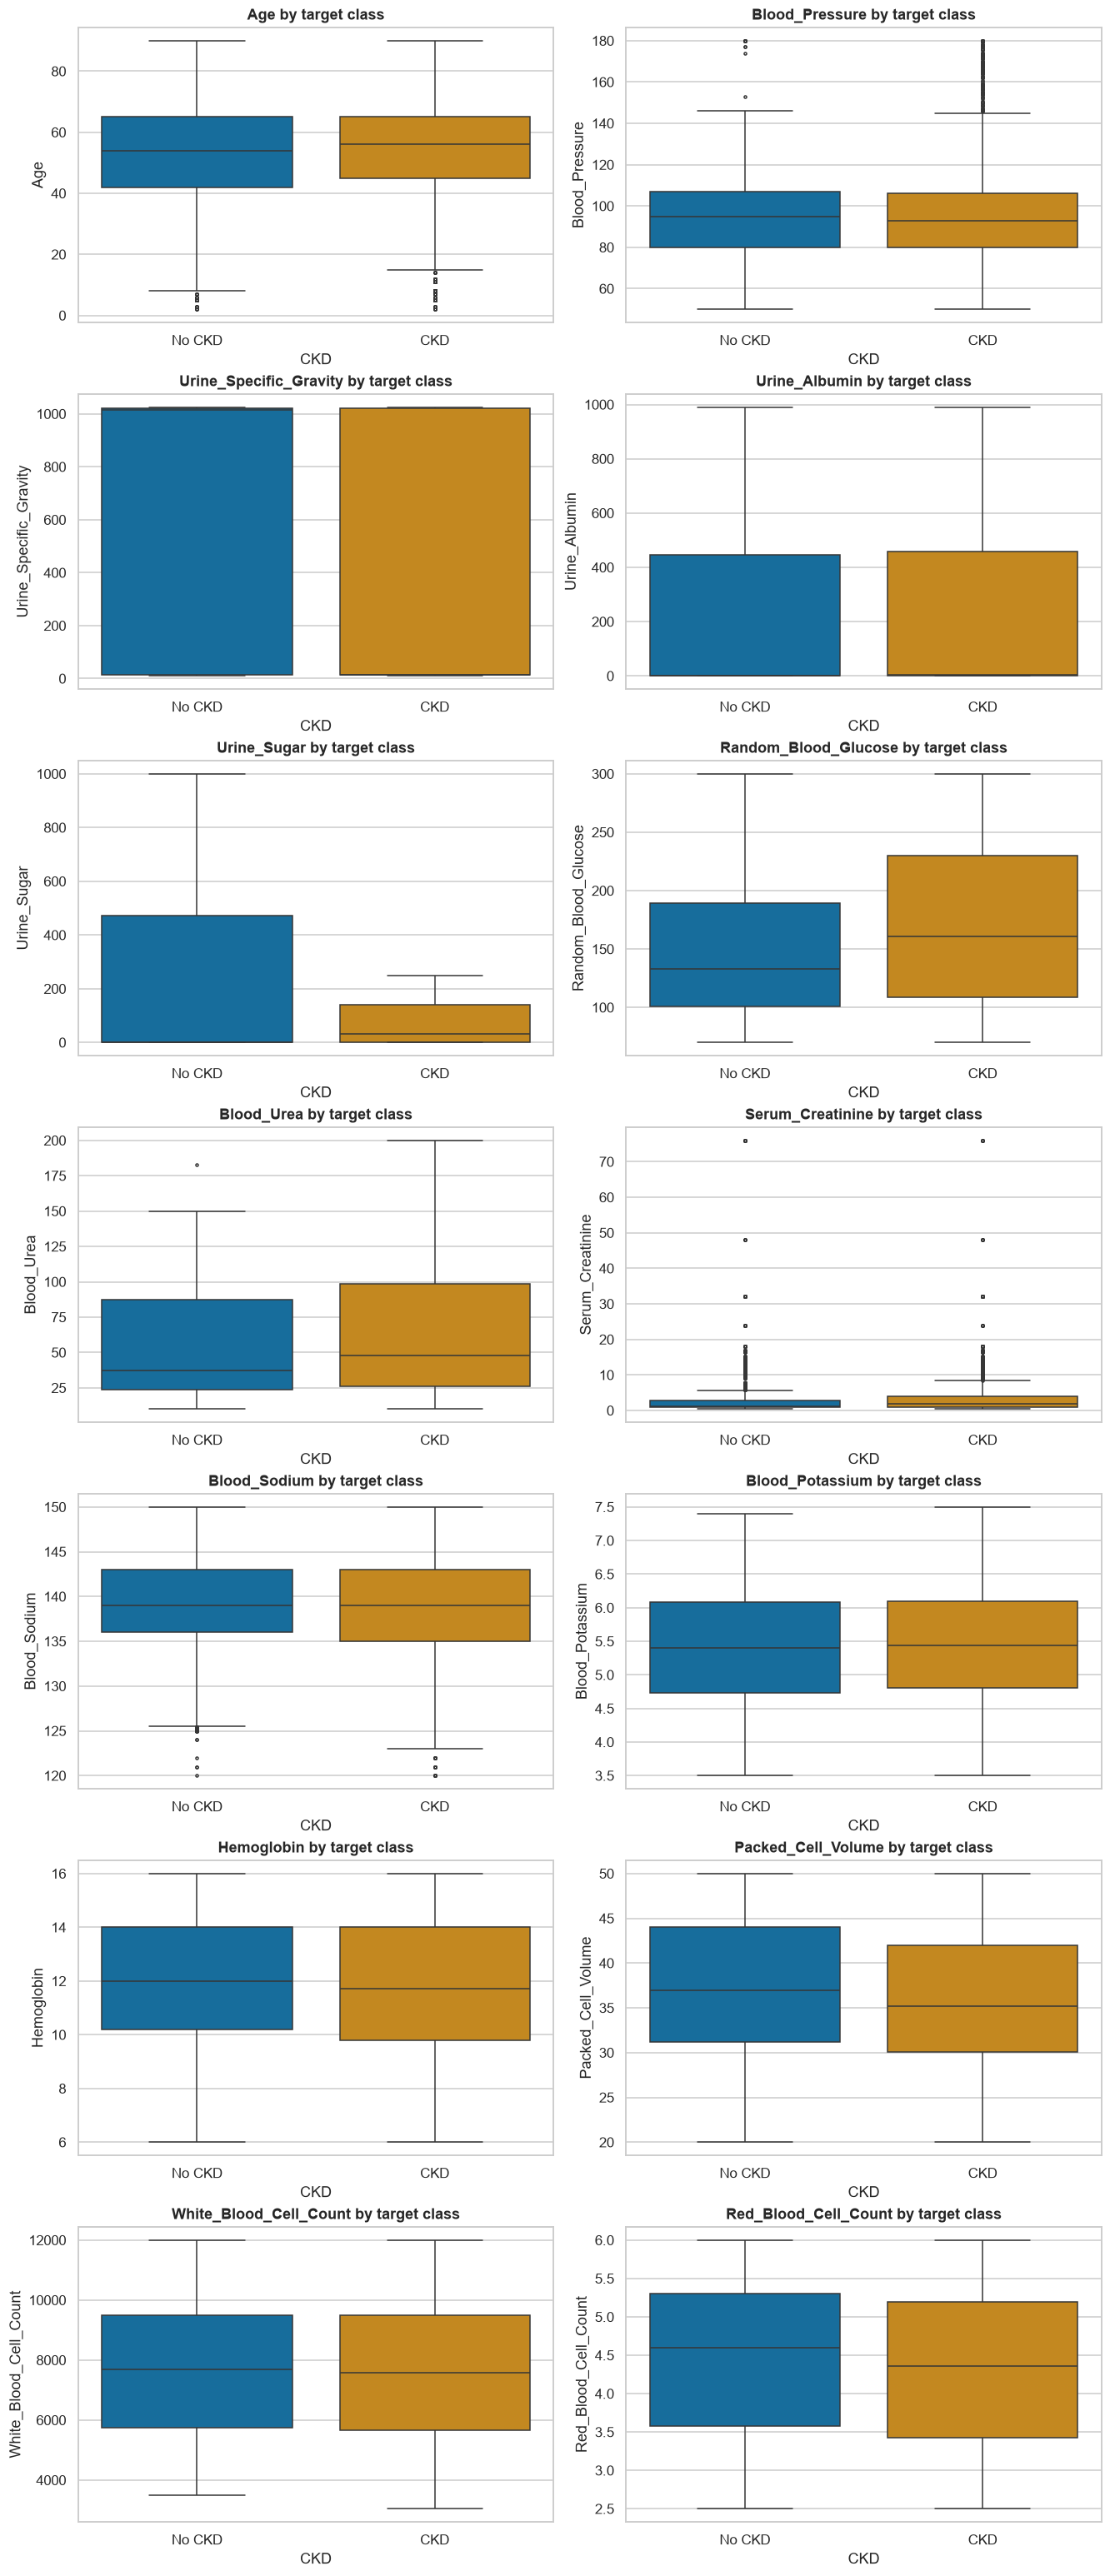

In [44]:
if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES))
    for ax, col in zip(axes, NUMERIC_FEATURES):
        sns.boxplot(
            data=df, x=CLASS_COL, y=col,
            order=class_order, hue=CLASS_COL,
            palette=class_colors, legend=False,
            fliersize=2, ax=ax
        )
        ax.set(title=f"{col} by target class", xlabel=TARGET)

    plt.show()


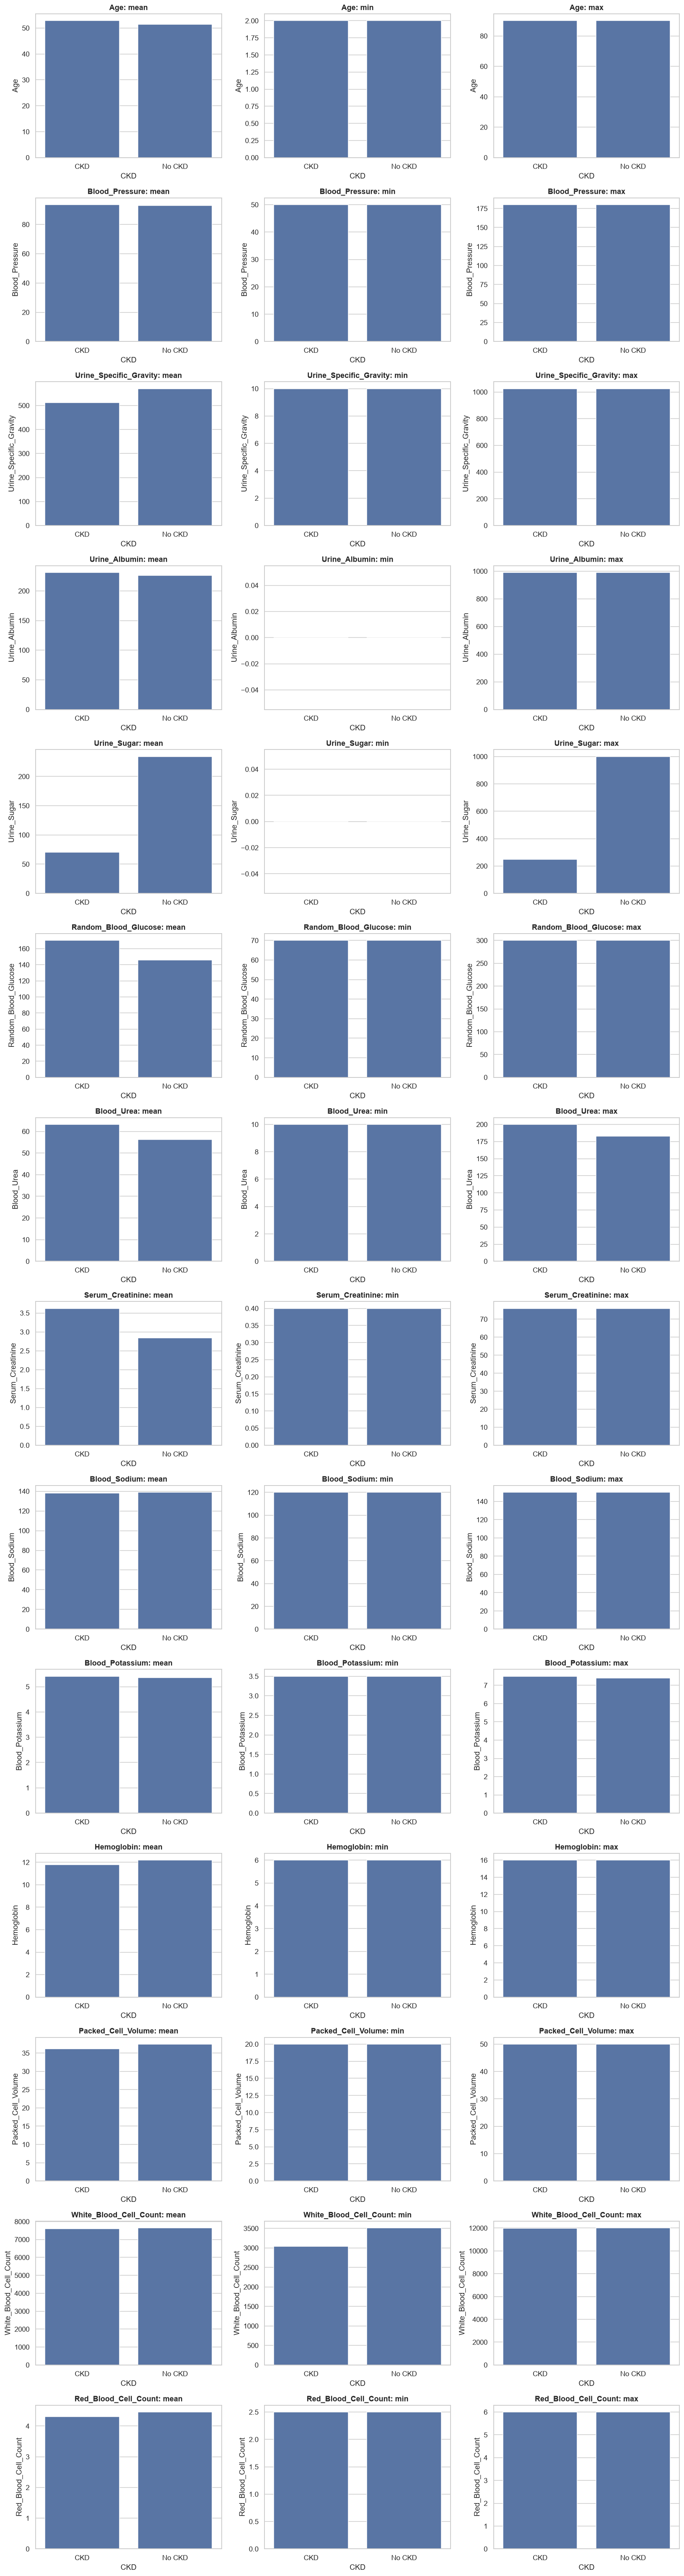

In [45]:
statistics = ["mean", "min", "max"]

plt.figure(figsize=(15, 4 * len(NUMERIC_FEATURES)))

plot_number = 1

for column in NUMERIC_FEATURES:
    for statistic in statistics:
        plt.subplot(len(NUMERIC_FEATURES), 3, plot_number)
        sns.barplot(
            data=df,
            x=CLASS_COL,
            y=column,
            estimator=statistic,
            errorbar=None
        )

        plt.title(f"{column}: {statistic}")
        plt.xlabel(TARGET)
        plot_number += 1

plt.tight_layout()
plt.show()

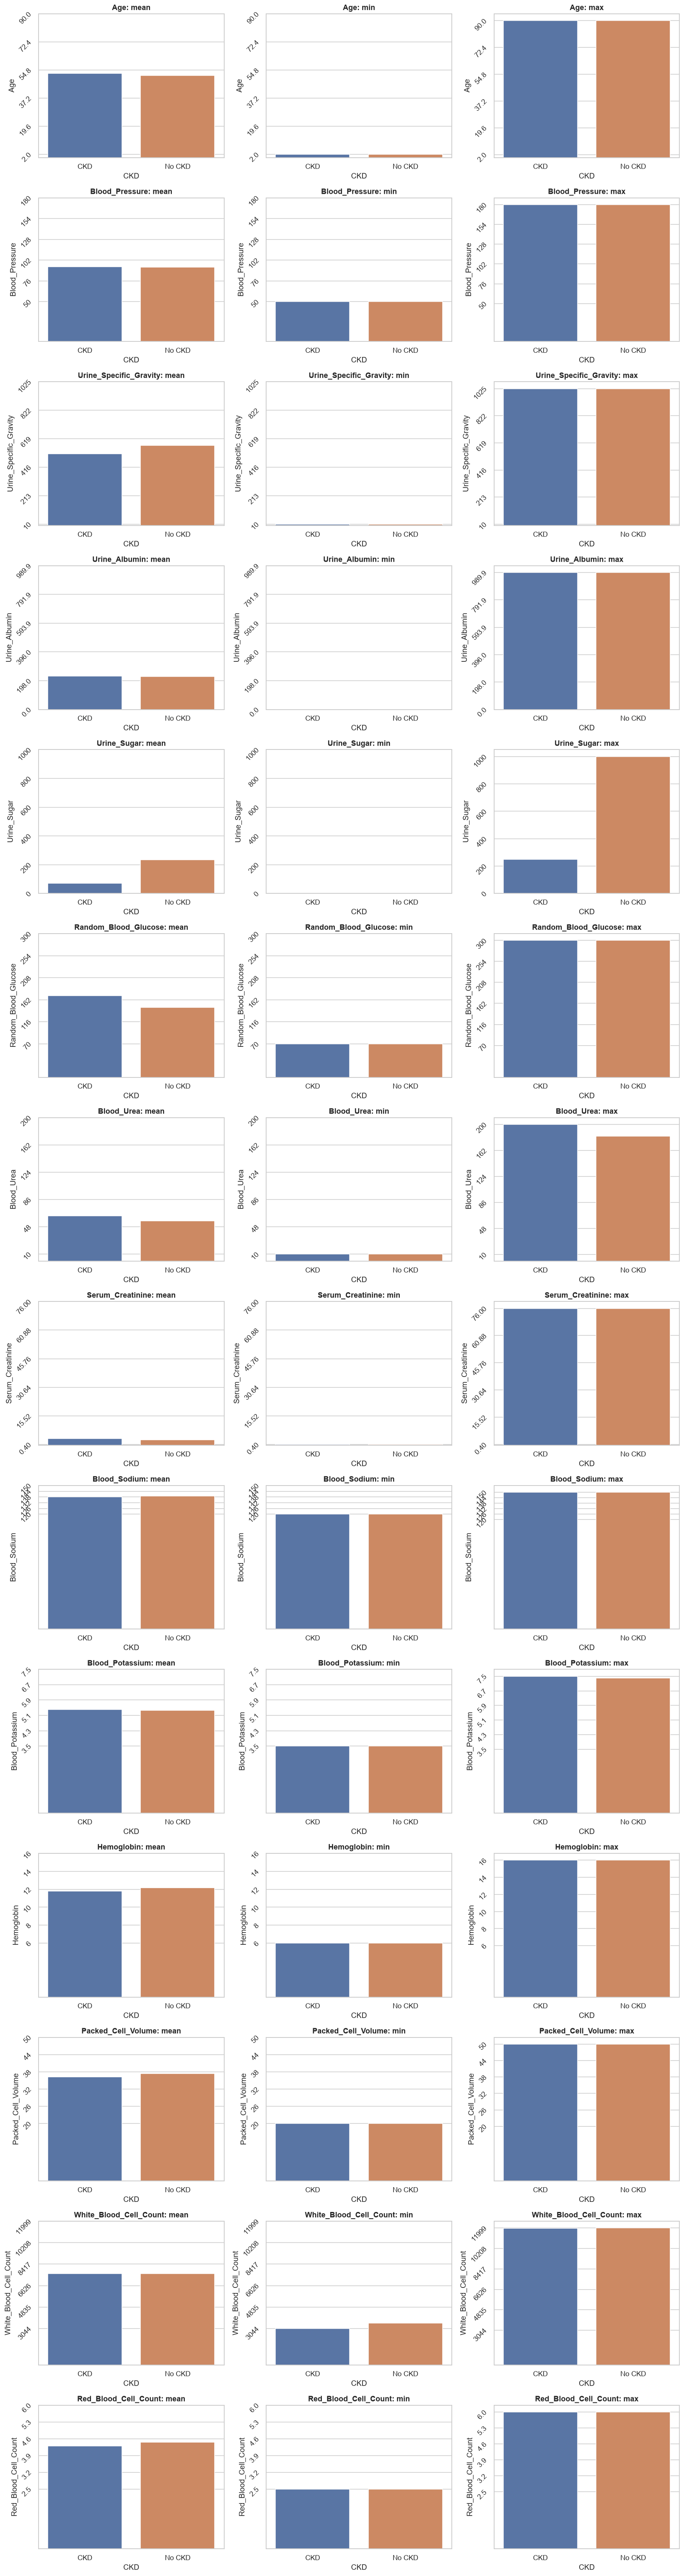

In [47]:
statistics = ["mean", "min", "max"]

plt.figure(figsize=(15, 4 * len(NUMERIC_FEATURES)))

plot_number = 1

for column in NUMERIC_FEATURES:
    for statistic in statistics:

        plt.subplot(len(NUMERIC_FEATURES), 3, plot_number)

        min_value = df[column].min()
        max_value = df[column].max()

        sns.barplot(
            data=df,
            x=CLASS_COL,
            y=column,
            hue=CLASS_COL,
            estimator=statistic,
            errorbar=None,
            legend=False
        )

        plt.title(f"{column}: {statistic}")
        plt.xlabel(TARGET)
        plt.yticks(np.linspace(min_value, max_value, 6), rotation=45)

        plot_number += 1

plt.tight_layout()
plt.show()

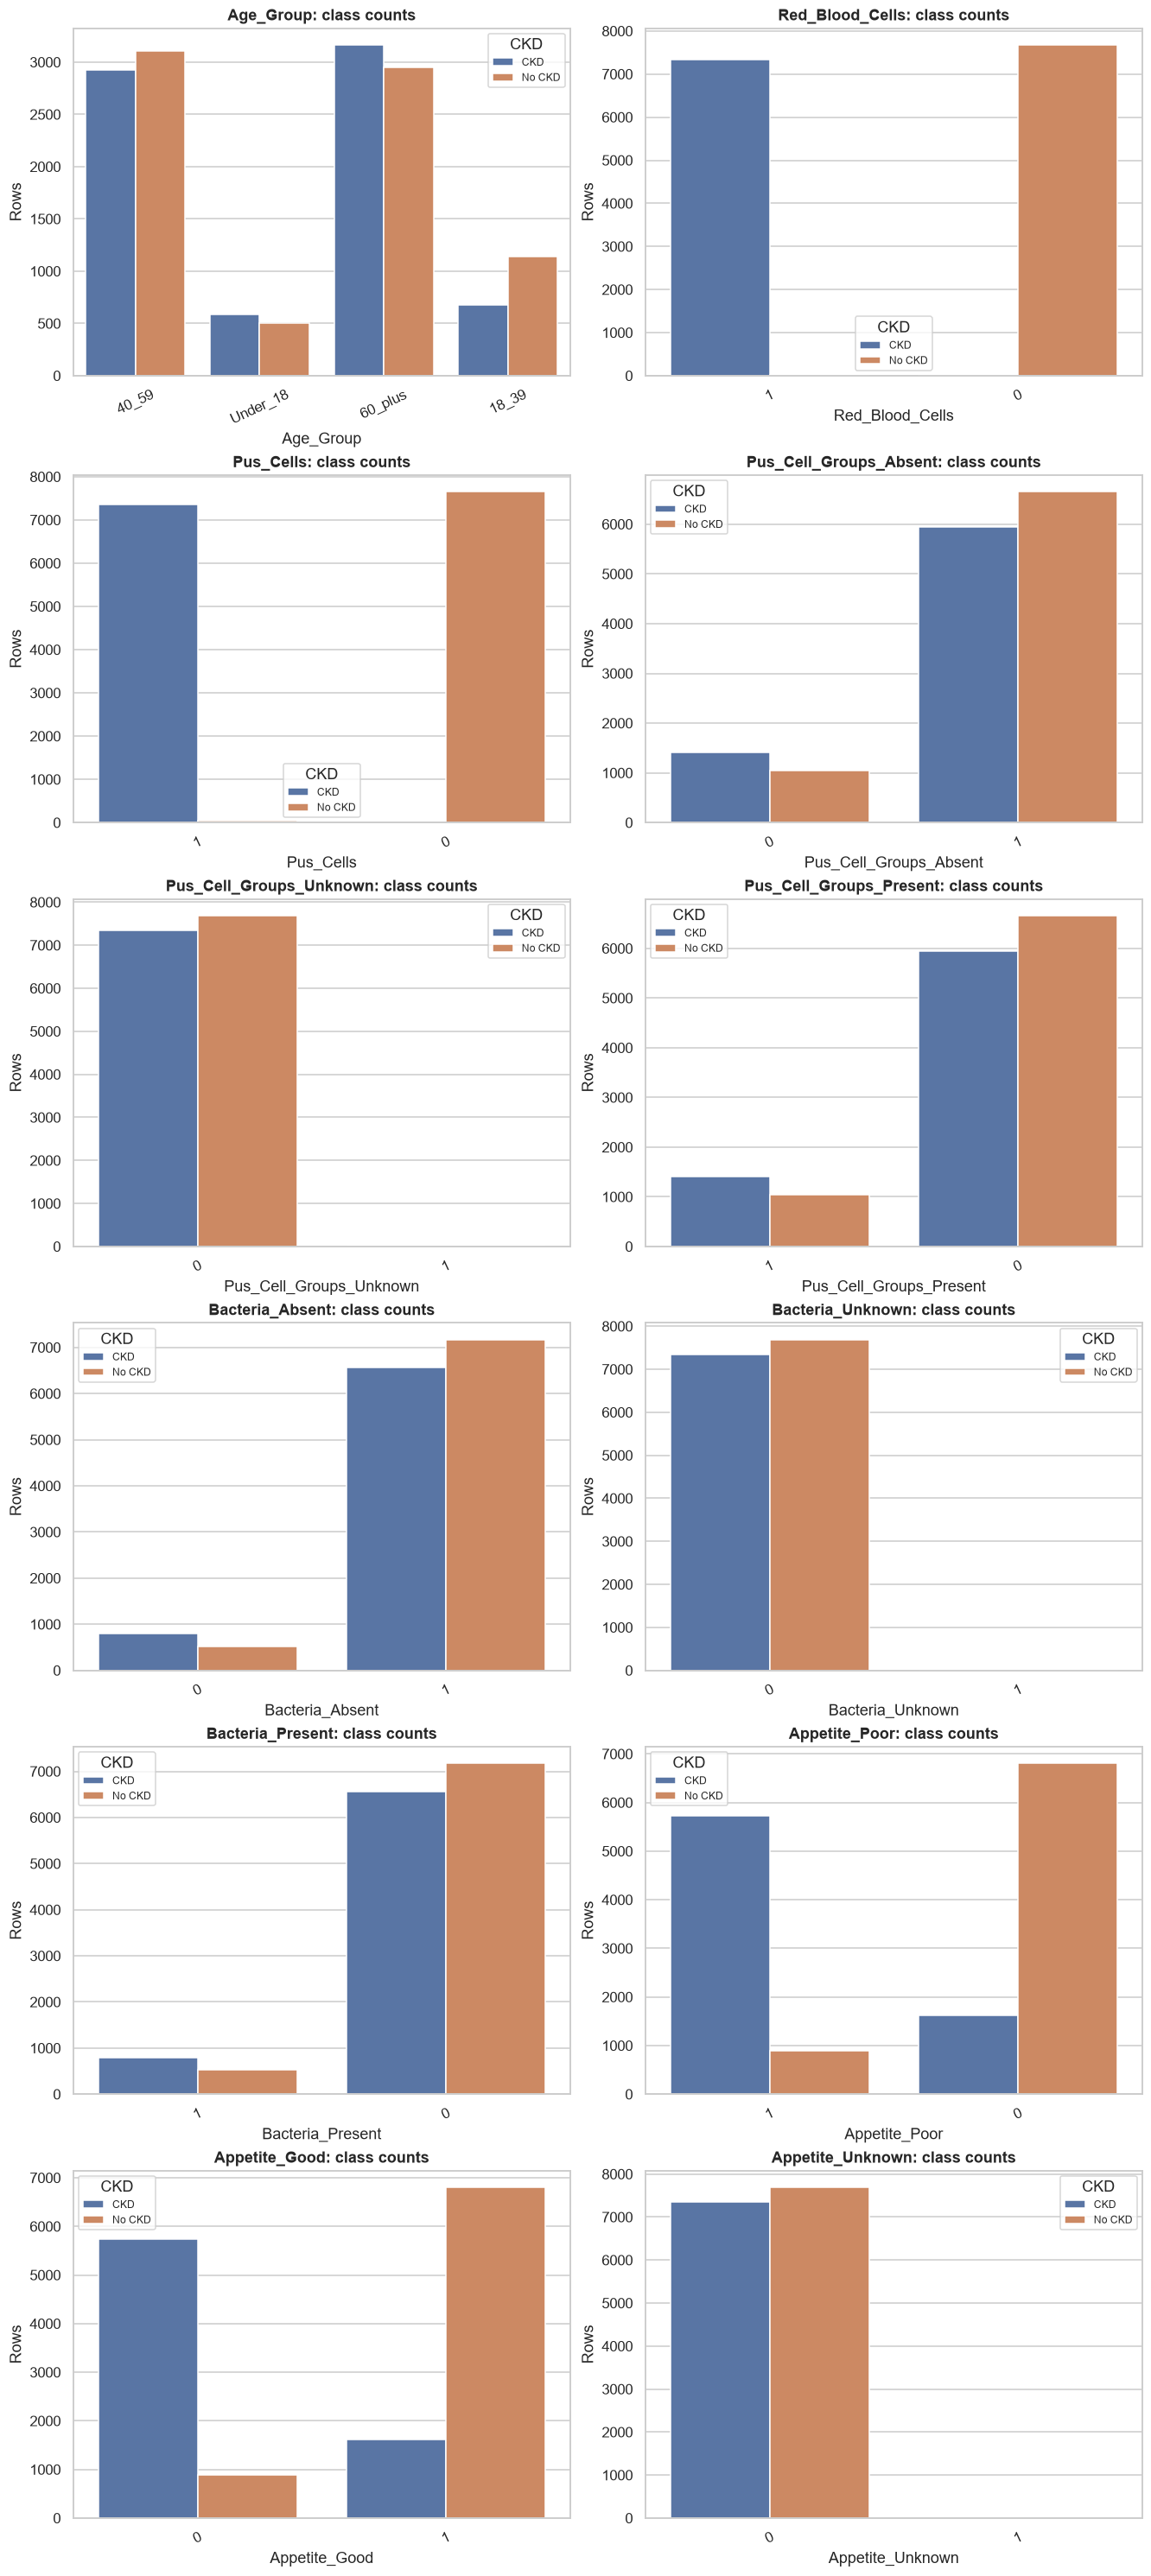

In [48]:
if CATEGORICAL_FEATURES:
    fig, axes = subplot_grid(len(CATEGORICAL_FEATURES), height=4.5)
    for ax, col in zip(axes, CATEGORICAL_FEATURES):
        sns.countplot(data=df, x=col, hue=CLASS_COL, ax=ax)
        # , order=category_orders[col],
        # hue_order=class_order, palette=class_colors,
        ax.set(title=f"{col}: class counts", ylabel="Rows")
        ax.tick_params(axis="x", rotation=25)
        ax.legend(title=TARGET, fontsize=8)
    plt.show()


Age_Group: percentages within each category


__target_label__,No CKD,CKD,n,small_group
Age_Group,,,,
60_plus,48.23,51.77,6115,False
40_59,51.51,48.49,6030,False
18_39,62.75,37.25,1812,False
Under_18,46.15,53.85,1092,False



Red_Blood_Cells: percentages within each category


__target_label__,No CKD,CKD,n,small_group
Red_Blood_Cells,,,,
0,99.88,0.12,7689,False
1,0.22,99.78,7360,False



Pus_Cells: percentages within each category


...

__target_label__,No CKD,CKD,n,small_group
Appetite_Poor,,,,
0,80.80,19.20,8426,False
1,13.41,86.59,6623,False



Appetite_Good: percentages within each category


__target_label__,No CKD,CKD,n,small_group
Appetite_Good,,,,
1,80.80,19.20,8425,False
0,13.42,86.58,6624,False



Appetite_Unknown: percentages within each category


__target_label__,No CKD,CKD,n,small_group
Appetite_Unknown,,,,
0,51.14,48.86,15048,False
1,100.00,0.00,1,True


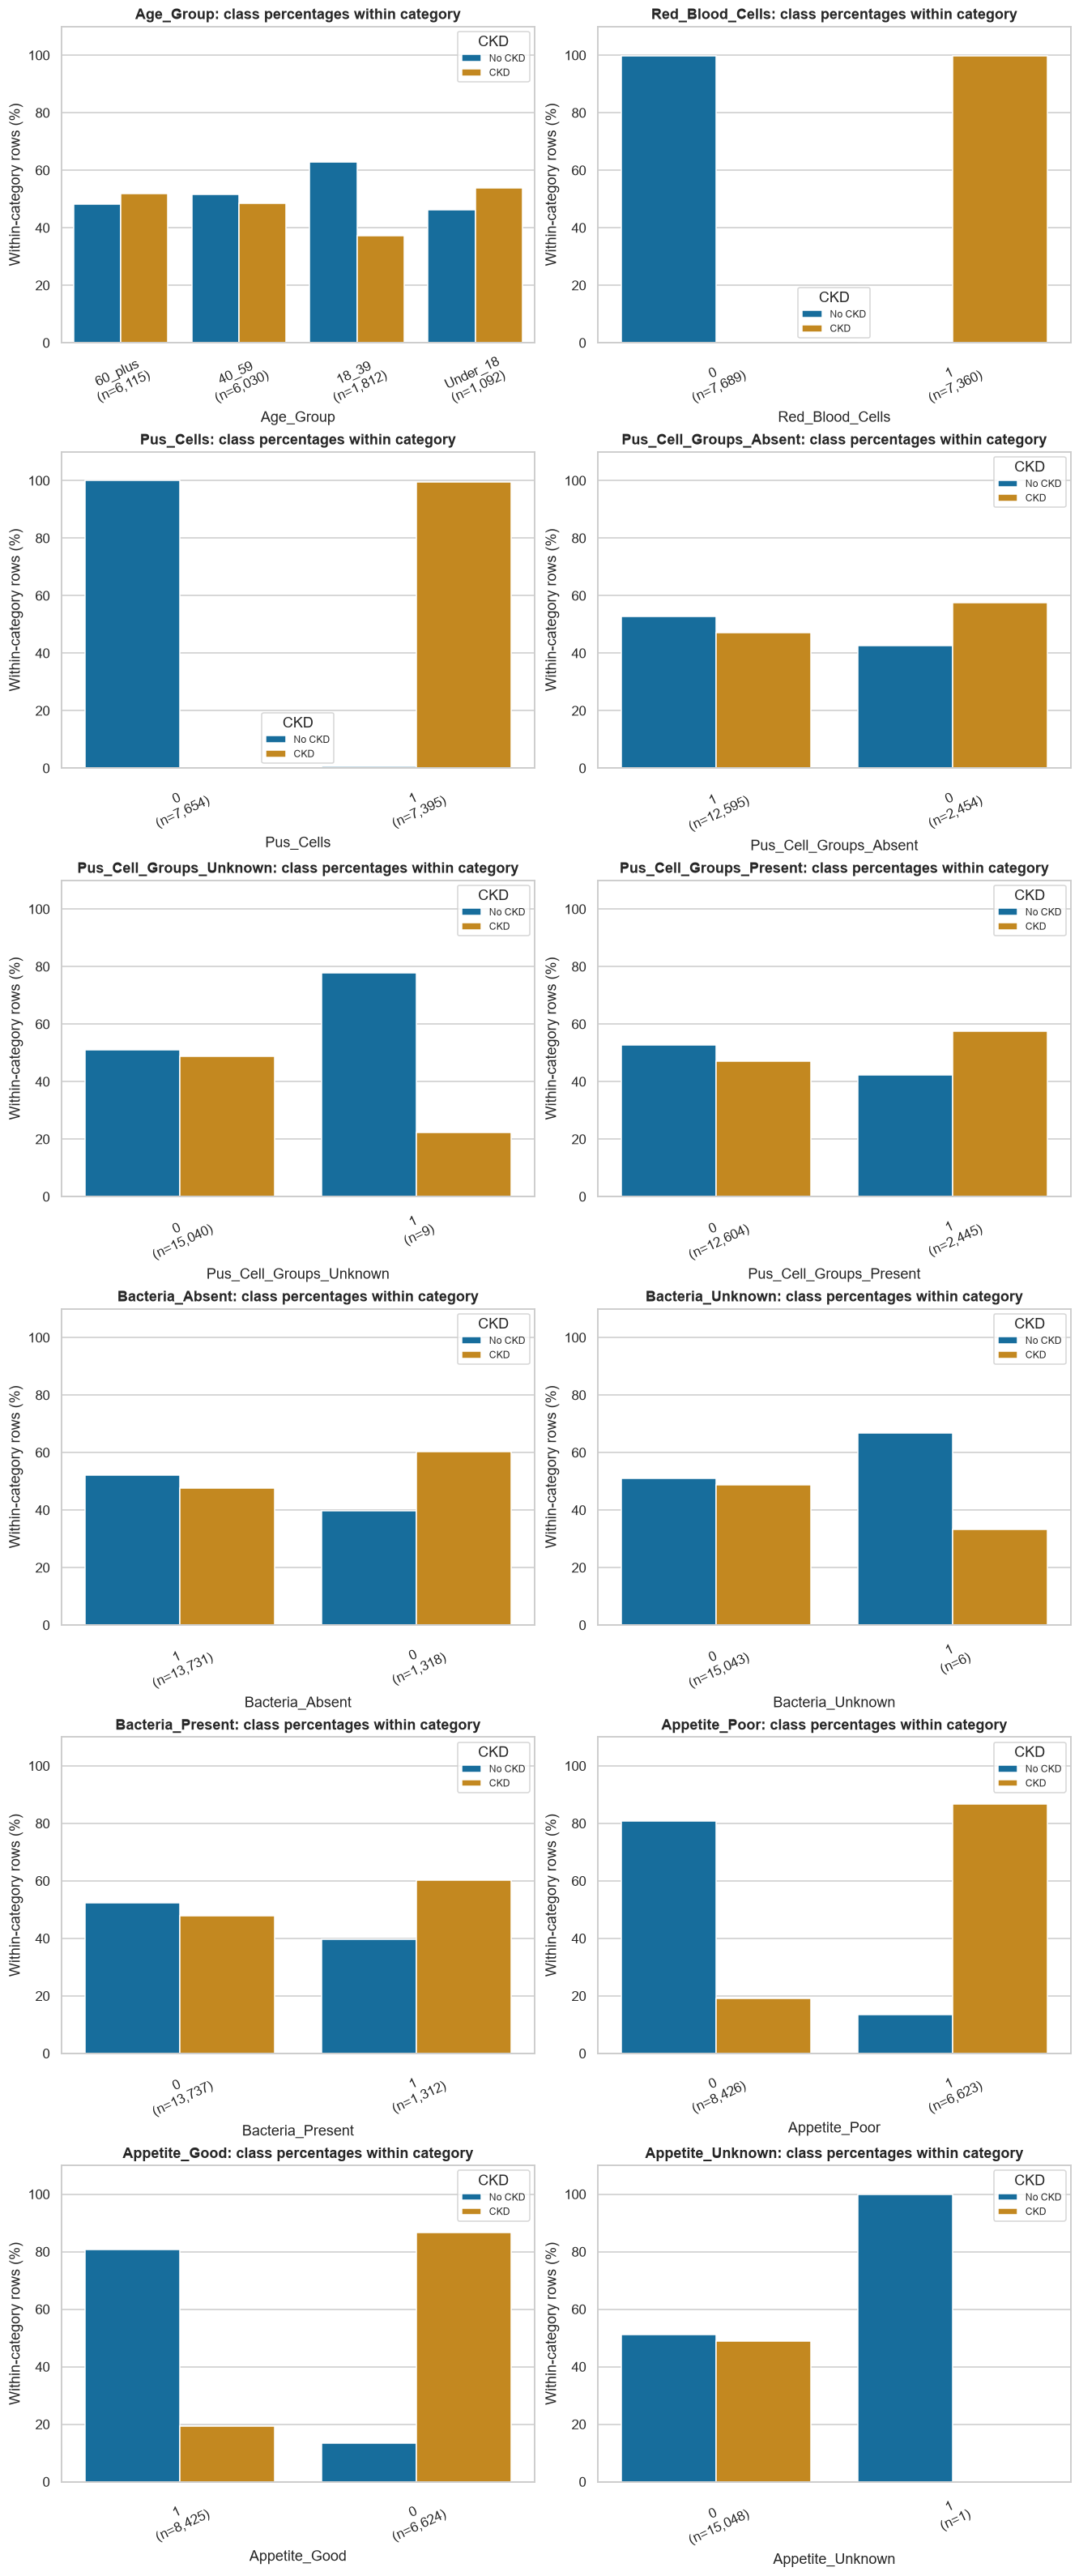

In [49]:
category_tables = {}
if CATEGORICAL_FEATURES:
    fig, axes = subplot_grid(len(CATEGORICAL_FEATURES), height=4.8)
    for ax, col in zip(axes, CATEGORICAL_FEATURES):
        counts = pd.crosstab(df[col], df[CLASS_COL]).reindex(
            index=category_orders[col], columns=class_order, fill_value=0)
        support = counts.sum(axis=1)
        percentages = counts.div(support, axis=0) * 100
        category_tables[col] = (counts, percentages)
        print(f"\n{col}: percentages within each category")
        display(percentages.round(2).assign(n=support, small_group=support < MIN_GROUP_SIZE))

        plot_rates = percentages.rename_axis(index="category", columns="target_class").reset_index()
        plot_rates = plot_rates.melt(id_vars="category", var_name="target_class", value_name="percent")
        sns.barplot(data=plot_rates, x="category", y="percent", hue="target_class",
                    order=category_orders[col], hue_order=class_order,
                    palette=class_colors, errorbar=None, ax=ax)
        ax.set(title=f"{col}: class percentages within category", xlabel=col,
               ylabel="Within-category rows (%)", ylim=(0, 110))
        ax.set_xticks(range(len(support)))
        ax.set_xticklabels([f"{cat}\n(n={support[cat]:,})" for cat in support.index], rotation=25)
        ax.legend(title=TARGET, fontsize=8)
    plt.show()